# MIRI Drug Efficacy Scoring — Pipeline & Visualization

This notebook runs the full MIRI drug efficacy scoring pipeline and produces publication-quality visualizations.

**Scoring methods:**
1. WCS + RGES — gene-set-based connectivity scoring
2. Zhang Score (ssCMap) — rank-based, preserves expression magnitude
3. Pathway-Level RGES — mechanistic pathway-reversal profiling

**Reference gene sets:**
- `MIRI_up-down.json` — union of 78 UP + 36 DOWN L1000 genes from 3 species
- `MIRI_rank.json` — 107 GSE160516 genes with signed ranks by |disease logFC|
- `MIRI_pathways.json` — 16 MIRI KEGG pathways with direction labels

**Output directories:**
- `scores/` — 4 CSV score files
- `plots/` — 7 PNG visualization files

## 0. Setup

In [6]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
from scipy.stats import spearmanr, pearsonr

# Project root
PROJECT_DIR = Path.cwd()
sys.path.insert(0, str(PROJECT_DIR / "scripts"))

# Output directories
SCORES_DIR = PROJECT_DIR / "scores"
PLOTS_DIR = PROJECT_DIR / "plots"
SCORES_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

from utils import load_drug_deg, load_gene_set, load_rank_reference, load_pathway_gene_sets
from score_wcs_rges import score_all_wcs_rges
from score_zhang import score_all_zhang
from score_pathway_rges import score_all_pathways
from run_all import integrate_scores

# Plotting defaults
%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook", palette="muted")
plt.rcParams.update({
    "figure.dpi": 120,
    "figure.figsize": (10, 6),
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
})

print(f"Project dir: {PROJECT_DIR}")
print(f"Scores dir:  {SCORES_DIR}")
print(f"Plots dir:   {PLOTS_DIR}")

Project dir: /home/chang/arc/MIRI-FDA_xscores
Scores dir:  /home/chang/arc/MIRI-FDA_xscores/scores
Plots dir:   /home/chang/arc/MIRI-FDA_xscores/plots


## 1. Run Scoring Pipeline

All three methods with z-score normalization. Output to `scores/`.

In [7]:
# Configuration
DEG_CSV = PROJECT_DIR / "xpert_fda-cm_deg.csv"
GENE_SET = PROJECT_DIR / "reference-genesets" / "MIRI_up-down.json"
RANK_REF = PROJECT_DIR / "reference-genesets" / "MIRI_rank.json"
PATHWAYS = PROJECT_DIR / "reference-genesets" / "MIRI_pathways.json"
USE_ZSCORE = True

# Score 1: WCS + RGES
print("=" * 60)
print("SCORE 1: WCS + RGES (gene-set based)")
print("=" * 60)
wcs_scores = score_all_wcs_rges(
    deg_csv_path=DEG_CSV,
    gene_set_path=GENE_SET,
    weight=1.0,
    output_path=SCORES_DIR / "scores_wcs_rges.csv",
    zscore=USE_ZSCORE,
)

# Score 2: Zhang Score (Type B: ranked reference)
print("\n" + "=" * 60)
print("SCORE 2: Zhang Score (rank-based, Type B)")
print("=" * 60)
zhang_scores = score_all_zhang(
    deg_csv_path=DEG_CSV,
    gene_set_path=None,
    rank_ref_path=RANK_REF,
    output_path=SCORES_DIR / "scores_zhang.csv",
    zscore=USE_ZSCORE,
)

# Score 3: Pathway-Level RGES
print("\n" + "=" * 60)
print("SCORE 3: Pathway-Level RGES")
print("=" * 60)
pw_scores = score_all_pathways(
    deg_csv_path=DEG_CSV,
    pathways_json_path=PATHWAYS,
    weight=1.0,
    output_path=SCORES_DIR / "scores_pathway_rges.csv",
    zscore=USE_ZSCORE,
)

# Integration
print("\n" + "=" * 60)
print("INTEGRATION: Combined Ranking")
print("=" * 60)
integrated = integrate_scores(
    wcs_scores, zhang_scores, pw_scores,
    output_path=SCORES_DIR / "fda_miri_scores_integrated.csv"
)
print(f"\nIntegrated ranking: {len(integrated)} drugs")

SCORE 1: WCS + RGES (gene-set based)
Loading DEG from /home/chang/arc/MIRI-FDA_xscores/xpert_fda-cm_deg.csv ...
  Applying per-gene z-score normalization...
  3127 drugs × 978 genes
Loading gene set from /home/chang/arc/MIRI-FDA_xscores/reference-genesets/MIRI_up-down.json ...
  MIRI_up-down: 78 UP, 36 DOWN (mapped to L1000)


Scoring WCS+RGES: 100%|██████████| 3127/3127 [00:00<00:00, 5945.81it/s]


Saved 3127 drugs to /home/chang/arc/MIRI-FDA_xscores/scores/scores_wcs_rges.csv

  Strong candidates (WCS < -0.2 AND RGES < -0.2): 5/3127
  Top 10:
                    drug_name       WCS      RGES  avg_rank
                    AVIBACTAM -0.300592 -0.216780      30.0
   PIOGLITAZONE HYDROCHLORIDE -0.283382 -0.218300      31.0
                   LUMACAFTOR -0.303582 -0.213465      31.5
                   PERFLEXANE -0.263255 -0.214984      39.0
          FLURBIPROFEN SODIUM -0.263249 -0.201497      49.5
    HISTAMINE DIHYDROCHLORIDE -0.267850 -0.199189      52.0
                EMPAGLIFLOZIN -0.305778 -0.177873      69.0
BENZHYDROCODONE HYDROCHLORIDE -0.239000 -0.172408     105.0
                 CAPECITABINE -0.270303 -0.166619     105.5
                   CONIVAPTAN -0.260391 -0.165730     111.5

SCORE 2: Zhang Score (rank-based, Type B)
Loading DEG from /home/chang/arc/MIRI-FDA_xscores/xpert_fda-cm_deg.csv ...
  Applying per-gene z-score normalization...
  3127 drugs × 978 genes
Load

Scoring Zhang (rank): 100%|██████████| 3127/3127 [00:01<00:00, 2720.03it/s]


Saved 3127 drugs to /home/chang/arc/MIRI-FDA_xscores/scores/scores_zhang.csv

  Strong candidates (Zhang c < -0.3): 696/3127
  Top 10:
              drug_name   Zhang_c  Zhang_p_approx
    VINCRISTINE SULFATE -0.603774             0.0
   COBIMETINIB FUMARATE -0.584670             0.0
       MIFAMURTIDE ACID -0.578456             0.0
    ERGOTAMINE TARTRATE -0.577400             0.0
    FORMOTEROL FUMARATE -0.575798             0.0
  PIMAVANSERIN TARTRATE -0.575126             0.0
ORITAVANCIN DIPHOSPHATE -0.572844             0.0
               ELBASVIR -0.569361             0.0
       BRILLIANT BLUE G -0.565051             0.0
          CISATRACURIUM -0.560087             0.0

SCORE 3: Pathway-Level RGES
Loading DEG from /home/chang/arc/MIRI-FDA_xscores/xpert_fda-cm_deg.csv ...
  Applying per-gene z-score normalization...
  3127 drugs × 978 genes
Loading pathways from /home/chang/arc/MIRI-FDA_xscores/reference-genesets/MIRI_pathways.json ...
  MIRI_KEGG_pathways: 16/16 pathways with ≥3

Scoring pathways: 100%|██████████| 3127/3127 [00:03<00:00, 998.02it/s] 


Saved 3127 drugs to /home/chang/arc/MIRI-FDA_xscores/scores/scores_pathway_rges.csv

  Top 10 by mean pathway efficacy:
               drug_name  mean_efficacy  n_effective  frac_effective
            CABOZANTINIB       0.513413           16          1.0000
               PONATINIB       0.453892           14          0.8750
              RIPRETINIB       0.435586           15          0.9375
GUANFACINE HYDROCHLORIDE       0.433100           15          0.9375
            FOSTAMATINIB       0.425905           15          0.9375
             COBIMETINIB       0.406455           14          0.8750
FLUOXETINE HYDROCHLORIDE       0.405108           14          0.8750
  PROCAINE HYDROCHLORIDE       0.392281           14          0.8750
        NAFCILLIN SODIUM       0.374930           14          0.8750
               RIOCIGUAT       0.366950           14          0.8750

INTEGRATION: Combined Ranking
Integrated scores saved to /home/chang/arc/MIRI-FDA_xscores/scores/fda_miri_scores_integra

## 2. Score Distributions

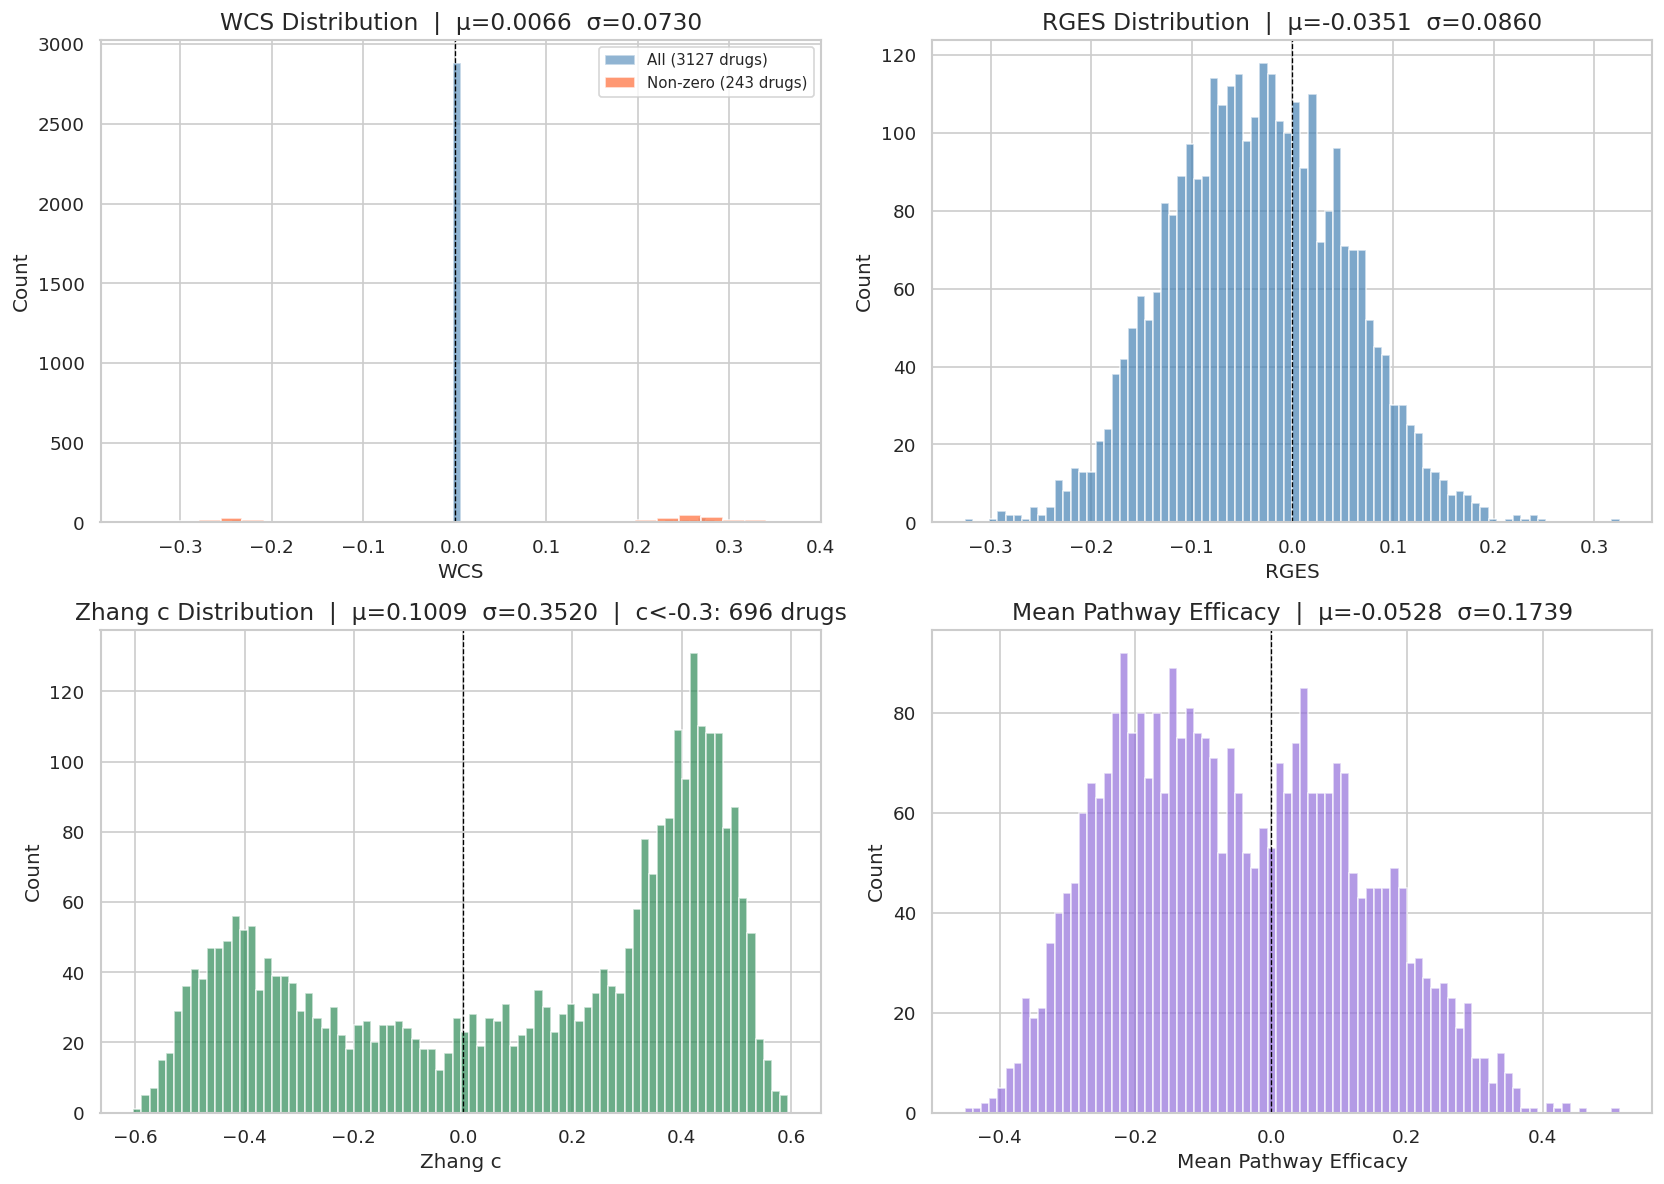

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ax = axes[0, 0]
nonzero_wcs = integrated[integrated["WCS"] != 0]["WCS"]
ax.hist(integrated["WCS"], bins=80, alpha=0.6, color="steelblue", label=f"All ({len(integrated)} drugs)")
ax.hist(nonzero_wcs, bins=30, alpha=0.8, color="coral", label=f"Non-zero ({len(nonzero_wcs)} drugs)")
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_xlabel("WCS")
ax.set_ylabel("Count")
ax.set_title(f"WCS Distribution  |  \u03bc={integrated['WCS'].mean():.4f}  \u03c3={integrated['WCS'].std():.4f}")
ax.legend(fontsize=9)

ax = axes[0, 1]
ax.hist(integrated["RGES"], bins=80, color="steelblue", alpha=0.7)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_xlabel("RGES")
ax.set_ylabel("Count")
ax.set_title(f"RGES Distribution  |  \u03bc={integrated['RGES'].mean():.4f}  \u03c3={integrated['RGES'].std():.4f}")

ax = axes[1, 0]
ax.hist(integrated["Zhang_c"], bins=80, color="seagreen", alpha=0.7)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_xlabel("Zhang c")
ax.set_ylabel("Count")
strong_mask = integrated["Zhang_c"] < -0.3
ax.set_title(f"Zhang c Distribution  |  \u03bc={integrated['Zhang_c'].mean():.4f}  \u03c3={integrated['Zhang_c'].std():.4f}  |  c<-0.3: {strong_mask.sum()} drugs")

ax = axes[1, 1]
ax.hist(integrated["mean_efficacy"], bins=80, color="mediumpurple", alpha=0.7)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_xlabel("Mean Pathway Efficacy")
ax.set_ylabel("Count")
ax.set_title(f"Mean Pathway Efficacy  |  \u03bc={integrated['mean_efficacy'].mean():.4f}  \u03c3={integrated['mean_efficacy'].std():.4f}")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "score_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Top 20 Drugs — Integrated Ranking

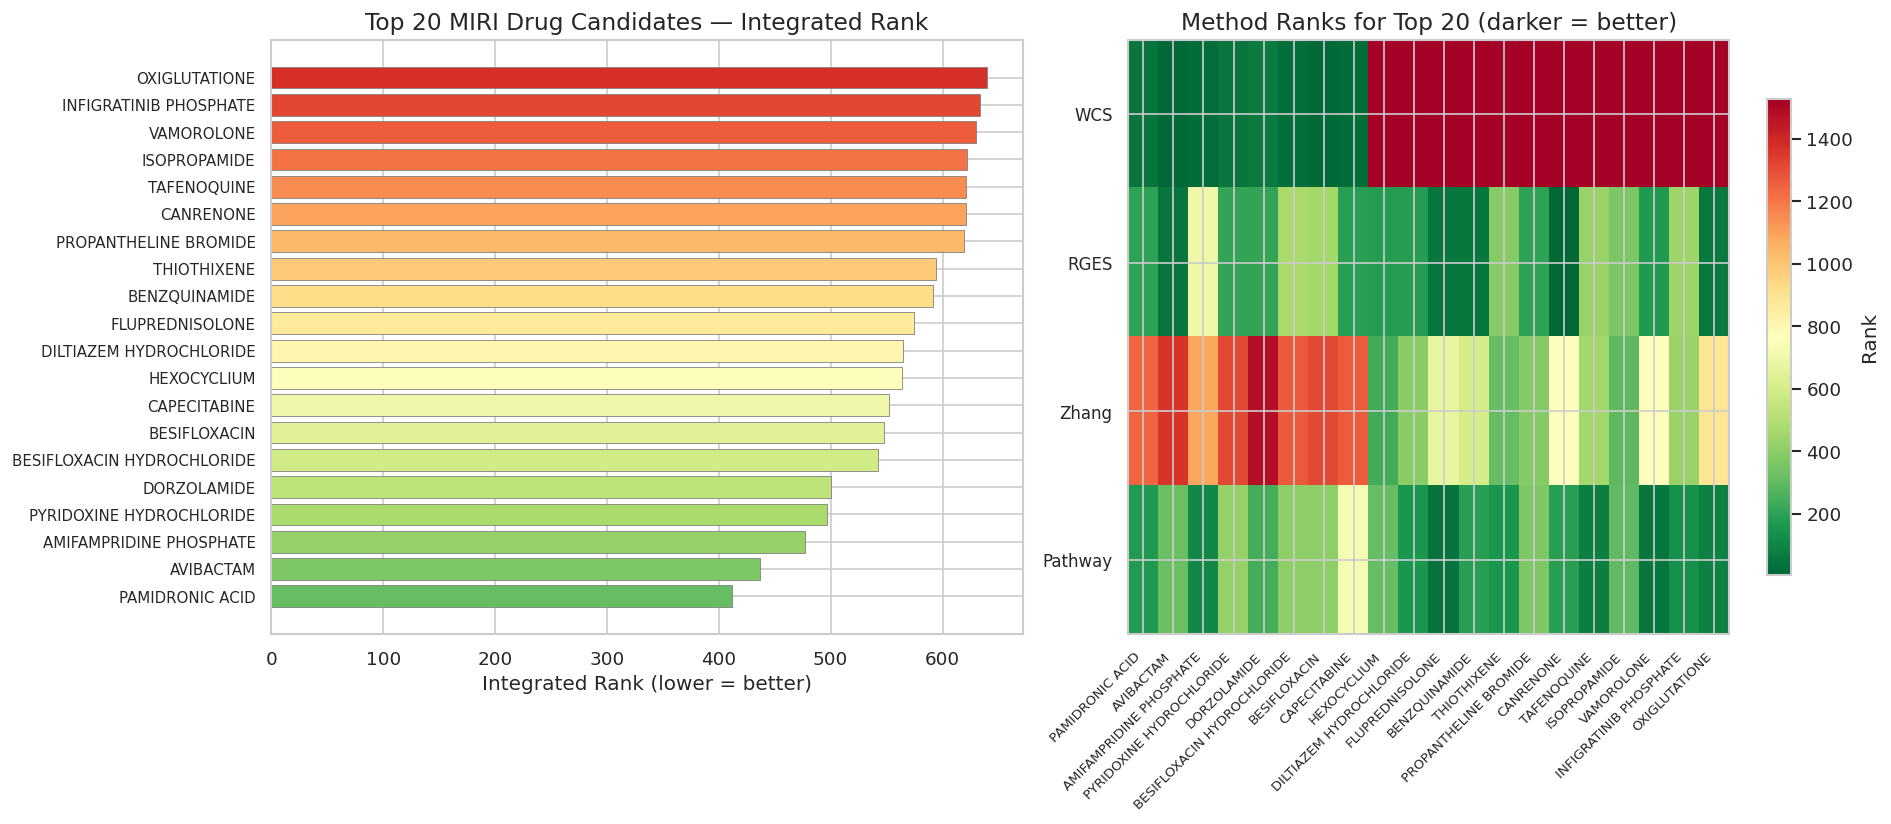

,drug_name,WCS,RGES,Zhang_c,mean_efficacy,n_effective,rank_integrated
10,PAMIDRONIC ACID,-0.2444,-0.1640,0.0468,0.2411,12,411.8
0,AVIBACTAM,-0.3006,-0.2168,0.1231,0.1833,10,436.8
22,AMIFAMPRIDINE PHOSPHATE,-0.2795,-0.1038,-0.0611,0.2704,12,477.2
11,PYRIDOXINE HYDROCHLORIDE,-0.2440,-0.1625,0.0848,0.1576,10,497.0
12,DORZOLAMIDE,-0.2215,-0.1613,0.1840,0.2051,10,500.2
18,BESIFLOXACIN HYDROCHLORIDE,-0.2611,-0.1265,0.0634,0.1633,11,542.0
17,BESIFLOXACIN,-0.2954,-0.1273,0.0864,0.1614,10,548.0
8,CAPECITABINE,-0.2703,-0.1666,0.0632,0.0884,11,552.5
204,HEXOCYCLIUM,0.0000,-0.1668,-0.4526,0.1877,13,563.9
202,DILTIAZEM HYDROCHLORIDE,0.0000,-0.1672,-0.4067,0.2443,14,564.6


In [9]:
top20 = integrated.head(20).copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

ax = axes[0]
colors = plt.cm.RdYlGn_r(np.linspace(0.2, 0.9, 20))
ax.barh(range(19, -1, -1), top20["rank_integrated"].values[::-1], color=colors[::-1], edgecolor="gray", linewidth=0.5)
ax.set_yticks(range(19, -1, -1))
ax.set_yticklabels(top20["drug_name"].values[::-1], fontsize=9)
ax.set_xlabel("Integrated Rank (lower = better)")
ax.set_title("Top 20 MIRI Drug Candidates — Integrated Rank")

ax = axes[1]
rank_cols = ["rank_WCS", "rank_RGES", "rank_Zhang", "rank_pathway"]
rank_data = top20[rank_cols].values
im = ax.imshow(rank_data.T, aspect="auto", cmap="RdYlGn_r", interpolation="nearest")
ax.set_xticks(range(20))
ax.set_xticklabels(top20["drug_name"].values, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(4))
ax.set_yticklabels(["WCS", "RGES", "Zhang", "Pathway"], fontsize=10)
ax.set_title("Method Ranks for Top 20 (darker = better)")
plt.colorbar(im, ax=ax, shrink=0.8, label="Rank")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "top20_integrated.png", dpi=150, bbox_inches="tight")
plt.show()

cols_show = ["drug_name", "WCS", "RGES", "Zhang_c", "mean_efficacy", "n_effective", "rank_integrated"]
display(top20[cols_show].style
    .background_gradient(subset=["WCS", "RGES"], cmap="RdYlGn_r")
    .background_gradient(subset=["Zhang_c"], cmap="RdYlGn")
    .format({"WCS": "{:.4f}", "RGES": "{:.4f}", "Zhang_c": "{:.4f}", "mean_efficacy": "{:.4f}", "rank_integrated": "{:.1f}"}))

## 4. Method Agreement Analysis

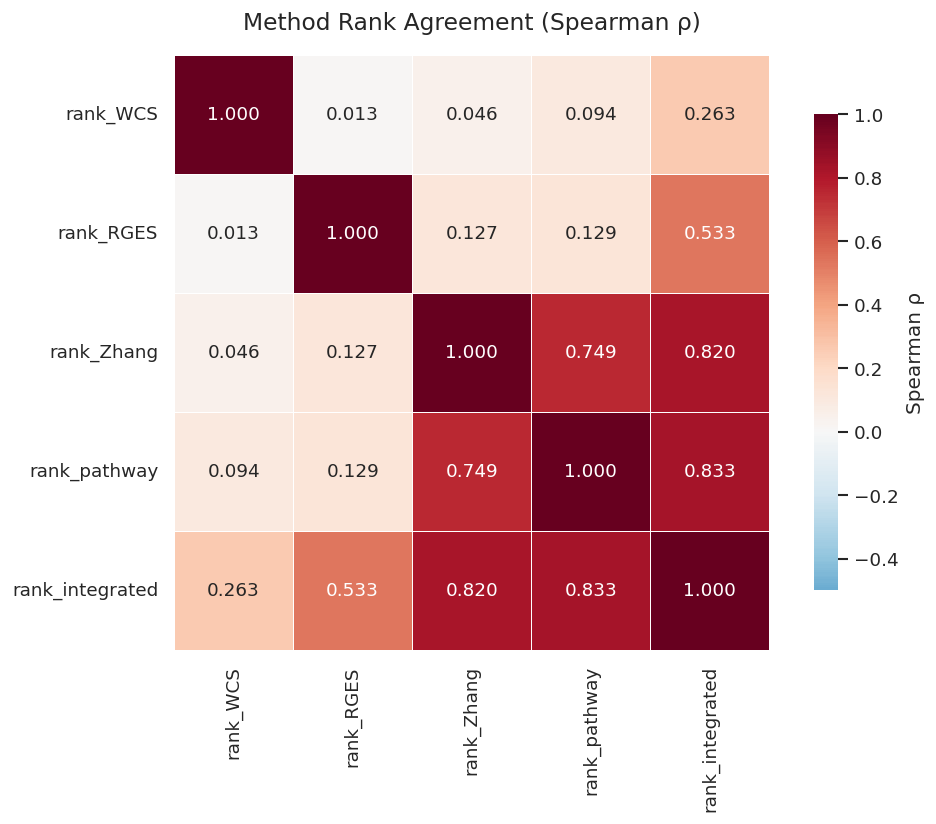

Method agreement summary:
  rank_WCS           vs rank_RGES         : ρ = +0.013  (p = 4.7e-01)
  rank_WCS           vs rank_Zhang        : ρ = +0.046  (p = 9.9e-03)
  rank_WCS           vs rank_pathway      : ρ = +0.094  (p = 1.5e-07)
  rank_WCS           vs rank_integrated   : ρ = +0.263  (p = 8.8e-51)
  rank_RGES          vs rank_Zhang        : ρ = +0.127  (p = 1.2e-12)
  rank_RGES          vs rank_pathway      : ρ = +0.129  (p = 5.5e-13)
  rank_RGES          vs rank_integrated   : ρ = +0.533  (p = 1.3e-228)
  rank_Zhang         vs rank_pathway      : ρ = +0.749  (p = 0.0e+00)
  rank_Zhang         vs rank_integrated   : ρ = +0.820  (p = 0.0e+00)
  rank_pathway       vs rank_integrated   : ρ = +0.833  (p = 0.0e+00)


In [10]:
rank_cols = ["rank_WCS", "rank_RGES", "rank_Zhang", "rank_pathway", "rank_integrated"]
rank_matrix = integrated[rank_cols].values
n_cols = len(rank_cols)

rho_matrix = np.zeros((n_cols, n_cols))
p_matrix = np.zeros((n_cols, n_cols))
for i in range(n_cols):
    for j in range(n_cols):
        rho, p = spearmanr(rank_matrix[:, i], rank_matrix[:, j])
        rho_matrix[i, j] = rho
        p_matrix[i, j] = p

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    rho_matrix,
    annot=True, fmt=".3f", cmap="RdBu_r", center=0,
    vmin=-0.5, vmax=1.0,
    xticklabels=rank_cols, yticklabels=rank_cols,
    square=True, linewidths=0.5,
    cbar_kws={"label": "Spearman \u03c1", "shrink": 0.8},
    ax=ax
)
ax.set_title("Method Rank Agreement (Spearman \u03c1)", fontsize=14, pad=15)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "method_agreement.png", dpi=150, bbox_inches="tight")
plt.show()

print("Method agreement summary:")
for i in range(n_cols - 1):
    for j in range(i + 1, n_cols):
        print(f"  {rank_cols[i]:18s} vs {rank_cols[j]:18s}: \u03c1 = {rho_matrix[i,j]:+.3f}  (p = {p_matrix[i,j]:.1e})")

### 4.1 Pairwise Scatter Plots

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
pairs = [
    ("WCS", "RGES", axes[0, 0]),
    ("WCS", "Zhang_c", axes[0, 1]),
    ("WCS", "mean_efficacy", axes[0, 2]),
    ("RGES", "Zhang_c", axes[1, 0]),
    ("RGES", "mean_efficacy", axes[1, 1]),
    ("Zhang_c", "mean_efficacy", axes[1, 2]),
]

for x_col, y_col, ax in pairs:
    x = integrated[x_col].values
    y = integrated[y_col].values
    rho, _ = spearmanr(x, y)
    r, _ = pearsonr(x, y)

    n_sample = min(2000, len(x))
    idx = np.random.RandomState(42).choice(len(x), n_sample, replace=False)
    ax.scatter(x[idx], y[idx], alpha=0.3, s=8, c="steelblue", edgecolors="none")
    ax.set_xlabel(x_col, fontsize=11)
    ax.set_ylabel(y_col, fontsize=11)
    ax.set_title(f"{x_col} vs {y_col}  |  \u03c1={rho:+.3f}  r={r:+.3f}")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "method_pairwise_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Pathway Reversal Profile — Top 10 Drugs

In [ ]:
# Load pathway scores from scores/
pw_full = pd.read_csv(SCORES_DIR / "scores_pathway_rges.csv")

pw_cols = [c for c in pw_full.columns if c.endswith("_efficacy")]
pw_names = [c.replace("_efficacy", "") for c in pw_cols]

top10_names = integrated.head(10)["drug_name"].values
top10_pw = pw_full[pw_full["drug_name"].isin(top10_names)].copy()
top10_pw = top10_pw.set_index("drug_name").reindex(top10_names)

fig, ax = plt.subplots(figsize=(14, 8))
heat_data = top10_pw[pw_cols].values
im = ax.imshow(heat_data, aspect="auto", cmap="RdBu_r", center=0, interpolation="nearest")
ax.set_xticks(range(len(pw_names)))
ax.set_xticklabels(pw_names, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(10))
ax.set_yticklabels(top10_names, fontsize=9)
ax.set_title("Pathway Reversal Profile — Top 10 MIRI Drug Candidates\n(red = reverses UP pathway, blue = reverses DOWN pathway)", fontsize=13, pad=15)
cbar = plt.colorbar(im, ax=ax, shrink=0.85)
cbar.set_label("Pathway Efficacy")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "pathway_heatmap_top10.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nPathway efficacy summary (all 3127 drugs):")
pw_summary = pd.DataFrame({
    "Pathway": pw_names,
    "Mean_Efficacy": [pw_full[c].mean() for c in pw_cols],
    "Std_Efficacy": [pw_full[c].std() for c in pw_cols],
}).sort_values("Mean_Efficacy")
display(pw_summary.style.bar(subset=["Mean_Efficacy"], color="steelblue"))

## 6. Consensus Analysis — Top 50 Overlap

In [ ]:
from matplotlib_venn import venn3

top50_wcs = set(integrated.nsmallest(50, "rank_WCS")["drug_name"])
top50_rges = set(integrated.nsmallest(50, "rank_RGES")["drug_name"])
top50_zhang = set(integrated.nsmallest(50, "rank_Zhang")["drug_name"])
top50_pw = set(integrated.nlargest(50, "mean_efficacy")["drug_name"])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

try:
    ax = axes[0]
    venn3([top50_rges, top50_zhang, top50_pw],
          set_labels=("RGES", "Zhang", "Pathway"), ax=ax)
    ax.set_title("Top-50 Overlap: RGES \u2229 Zhang \u2229 Pathway")
except ImportError:
    axes[0].text(0.5, 0.5, "matplotlib_venn not installed\nrun: pip install matplotlib-venn",
                 transform=axes[0].transAxes, ha="center", va="center", fontsize=12)
    axes[0].set_title("Venn Diagram (unavailable)")

ax = axes[1]
categories = ["WCS", "RGES", "Zhang", "Pathway"]
sets = [top50_wcs, top50_rges, top50_zhang, top50_pw]
overlap_counts = []
overlap_labels = []

all4 = top50_wcs & top50_rges & top50_zhang & top50_pw
overlap_counts.append(len(all4))
overlap_labels.append(f"All 4\n({len(all4)})")

for i, (s1_name, s1) in enumerate(zip(categories, sets)):
    others = [s for j, s in enumerate(sets) if j != i]
    three_way = others[0] & others[1] & others[2] - s1
    overlap_counts.append(len(three_way))
    overlap_labels.append(f"All except\n{s1_name}\n({len(three_way)})")

ax.bar(range(len(overlap_labels)), overlap_counts, color="steelblue", edgecolor="gray")
ax.set_xticks(range(len(overlap_labels)))
ax.set_xticklabels(overlap_labels, fontsize=9)
ax.set_ylabel("Number of Drugs")
ax.set_title("Top-50 Method Consensus")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "top50_consensus.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Consensus top-50 (all 4 methods agree): {len(all4)} drugs")
if all4:
    print(f"  {sorted(all4)}")
print(f"\nPer-method top 50:")
print(f"  WCS:      {len(top50_wcs)} drugs")
print(f"  RGES:     {len(top50_rges)} drugs")
print(f"  Zhang:    {len(top50_zhang)} drugs")
print(f"  Pathway:  {len(top50_pw)} drugs")

## 7. Score Profile: Top 50 vs Bottom 50

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

top50_df = integrated.head(50).copy()
bottom50_df = integrated.tail(50).copy()

x_labels = ["WCS", "RGES", "Zhang_c", "mean_efficacy"]
x = np.arange(len(x_labels))
width = 0.35

def normalize_minmax(s):
    return (s - s.min()) / (s.max() - s.min()) if s.max() > s.min() else s

top_vals = [normalize_minmax(top50_df[c]) if c != "Zhang_c" else -normalize_minmax(-top50_df[c]) for c in x_labels]
bot_vals = [normalize_minmax(bottom50_df[c]) if c != "Zhang_c" else -normalize_minmax(-bottom50_df[c]) for c in x_labels]

top_means = [v.mean() for v in top_vals]
bot_means = [v.mean() for v in bot_vals]

ax.bar(x - width/2, top_means, width, label="Top 50 (best)", color="forestgreen", alpha=0.8, edgecolor="gray")
ax.bar(x + width/2, bot_means, width, label="Bottom 50 (worst)", color="lightcoral", alpha=0.8, edgecolor="gray")
ax.set_xticks(x)
ax.set_xticklabels(x_labels, fontsize=11)
ax.set_ylabel("Normalized Score (0=best, 1=worst)")
ax.set_title("Score Profile: Top 50 vs Bottom 50")
ax.legend()

plt.tight_layout()
plt.savefig(PLOTS_DIR / "top_vs_bottom.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Export Summary

In [ ]:
print("=" * 70)
print("MIRI Drug Efficacy Scoring — Results Summary")
print("=" * 70)
print(f"\nDrugs scored:  {len(integrated)}")
print(f"Z-score norm:   {USE_ZSCORE}")
print(f"Gene set:       {GENE_SET.name}")
print(f"Rank ref:       {RANK_REF.name}")
print(f"Pathways:       {PATHWAYS.name}")

print(f"\n── Score Ranges ──")
print(f"  WCS:           [{integrated['WCS'].min():+.4f}, {integrated['WCS'].max():+.4f}]")
print(f"  RGES:          [{integrated['RGES'].min():+.4f}, {integrated['RGES'].max():+.4f}]")
print(f"  Zhang c:       [{integrated['Zhang_c'].min():+.4f}, {integrated['Zhang_c'].max():+.4f}]")
print(f"  Pathway eff:   [{integrated['mean_efficacy'].min():+.4f}, {integrated['mean_efficacy'].max():+.4f}]")

print(f"\n── Top 5 Candidates ──")
for i, row in integrated.head(5).iterrows():
    print(f"  {row['drug_name']:35s}  WCS={row['WCS']:+.4f}  RGES={row['RGES']:+.4f}  Zhang={row['Zhang_c']:+.4f}  PW={row['mean_efficacy']:+.4f}  rank={row['rank_integrated']:.1f}")

print(f"\n── Cross-Method Agreement ──")
for (a, b) in [("rank_WCS", "rank_RGES"), ("rank_WCS", "rank_Zhang"), ("rank_RGES", "rank_Zhang"), ("rank_WCS", "rank_pathway")]:
    rho, p = spearmanr(integrated[a], integrated[b])
    print(f"  {a:18s} vs {b:18s}: \u03c1 = {rho:+.3f}  (p = {p:.1e})")

print(f"\n── Output Files (scores/) ──")
for f in ["scores_wcs_rges.csv", "scores_zhang.csv", "scores_pathway_rges.csv", "fda_miri_scores_integrated.csv"]:
    path = SCORES_DIR / f
    size_kb = path.stat().st_size / 1024 if path.exists() else 0
    print(f"  {str(path):55s} {size_kb:8.0f} KB")

print(f"\n── Output Files (plots/) ──")
for f in ["score_distributions.png", "top20_integrated.png", "method_agreement.png", "method_pairwise_scatter.png", "pathway_heatmap_top10.png", "top50_consensus.png", "top_vs_bottom.png"]:
    path = PLOTS_DIR / f
    size_kb = path.stat().st_size / 1024 if path.exists() else 0
    print(f"  {str(path):55s} {size_kb:8.0f} KB")

print("\n\u2713 Scoring pipeline complete.")